1. Import Library

In [318]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

2. Load Data

In [319]:
NAMA_SHEET = "indomie"
FILE_EXCEL = "dataset/data_clean.xlsx"



In [320]:
df = pd.read_excel(
    FILE_EXCEL,
    sheet_name=NAMA_SHEET
)

df['ds'] = pd.to_datetime(df['ds'])

df.head()

,ds,y
0,2023-01-01,6
1,2023-01-02,11
2,2023-01-03,7
3,2023-01-04,4
4,2023-01-05,7


Preprocessing Data

In [321]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

#urutkan data
df = df.sort_values('ds')

#cek missing value
df = df.sort_values('ds')
df = df.dropna()


In [322]:
#cek data duplikat
df.duplicated().sum()

0

In [323]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean        8.519231
std         5.414666
min         0.000000
25%         5.000000
50%         8.000000
75%        10.000000
max        81.000000
Name: y, dtype: float64

In [324]:
#jumlah data 0 
print( "Jumlah data 0:", (df['y'] == 0).sum() )

Jumlah data 0: 5


Visualisasi Penjualan

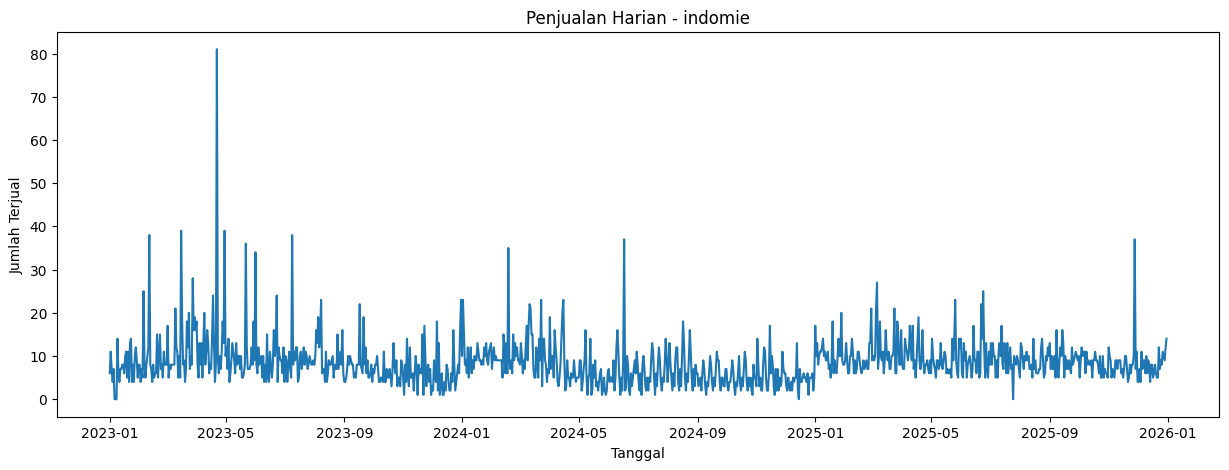

In [325]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title(f"Penjualan Harian - {NAMA_SHEET}")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

Analisis Penjualan Pertahun

In [326]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023    9.112329
2024    7.104972
2025    9.328767
Name: y, dtype: float64

Split Data Train-Test

In [327]:
train = df[df['ds'] < '2025-07-01']
test = df[df['ds'] >= '2025-07-01']

print("Train:", len(train))
print("Test:", len(test))

Train: 908
Test: 184


Training Prophet

In [328]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

model.fit(train)

20:56:50 - cmdstanpy - INFO - Chain [1] start processing
20:56:50 - cmdstanpy - INFO - Chain [1] done processing


Evaluasi

In [329]:
future_test = model.make_future_dataframe(
    periods=len(test)
)

forecast_test = model.predict(
    future_test
)

hasil = test.merge(
    forecast_test[['ds','yhat']], on='ds'
)

hasil.head()

,ds,y,tahun,yhat
0,2025-07-01,8,2025,9.039741
1,2025-07-02,13,2025,8.603519
2,2025-07-03,8,2025,8.805776
3,2025-07-04,13,2025,9.301463
4,2025-07-05,10,2025,9.487504


Hitung Eror

In [330]:
mae = mean_absolute_error(
    hasil['y'],
    hasil['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        hasil['y'],
        hasil['yhat']
    )
)

smape = (
    np.mean(np.abs(hasil['y'] - hasil['yhat'])
    /
    ((np.abs(hasil['y']) + np.abs(hasil['yhat']))/ 2)
    )) * 100

print("MAE:", round(mae))
print("RMSE:", round(rmse))
print("SMAPE:", round(smape,2),"%")

MAE: 2
RMSE: 3
SMAPE: 26.81 %


PrediksI Data Test

In [331]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)
# print (forecast)

In [332]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]
print (pred_test)

             ds       yhat
908  2025-07-01   9.039741
909  2025-07-02   8.603519
910  2025-07-03   8.805776
911  2025-07-04   9.301463
912  2025-07-05   9.487504
...         ...        ...
1087 2025-12-27   9.956892
1088 2025-12-28  10.909069
1089 2025-12-29  10.168485
1090 2025-12-30   9.914071
1091 2025-12-31   9.727044

[184 rows x 2 columns]


Visualisasi Data Aktual VS Prediksi

In [333]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

print (evaluation)

            ds   y  tahun       yhat
0   2025-07-01   8   2025   9.039741
1   2025-07-02  13   2025   8.603519
2   2025-07-03   8   2025   8.805776
3   2025-07-04  13   2025   9.301463
4   2025-07-05  10   2025   9.487504
..         ...  ..    ...        ...
179 2025-12-27  11   2025   9.956892
180 2025-12-28  10   2025  10.909069
181 2025-12-29   9   2025  10.168485
182 2025-12-30  12   2025   9.914071
183 2025-12-31  14   2025   9.727044

[184 rows x 4 columns]


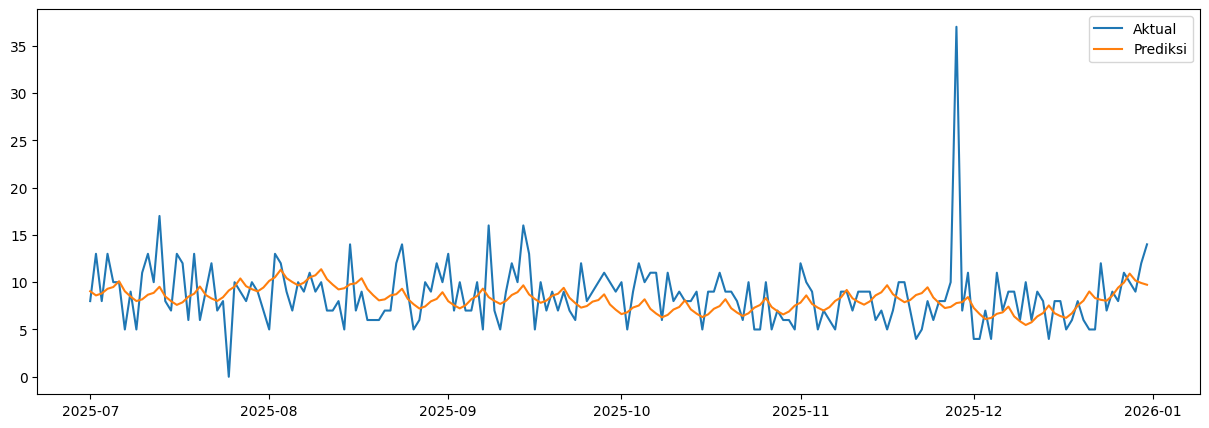

In [334]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

Analisis Eror Terbesar

In [335]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
150,2025-11-28,37,2025,7.792767,29.207233
24,2025-07-25,0,2025,9.120031,9.120031
69,2025-09-08,16,2025,8.418702,7.581298
12,2025-07-13,17,2025,9.515390,7.484610
75,2025-09-14,16,2025,9.668770,6.331230
15,2025-07-16,13,2025,7.601031,5.398969
31,2025-08-01,5,2025,10.137503,5.137503
62,2025-09-01,13,2025,7.991498,5.008502
54,2025-08-24,14,2025,9.306838,4.693162
85,2025-09-24,12,2025,7.310324,4.689676


Training Final Menggunakan Seluruh Data

In [336]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

final_model.fit(df[['ds','y']])
print (final_model)

20:56:51 - cmdstanpy - INFO - Chain [1] start processing
20:56:52 - cmdstanpy - INFO - Chain [1] done processing


Forecast 14 Hari

In [337]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14
print (forecast_14)

             ds       yhat
1092 2026-01-01  10.289514
1093 2026-01-02  11.143443
1094 2026-01-03  11.530856
1095 2026-01-04  12.263925
1096 2026-01-05  11.369175
1097 2026-01-06  10.983029
1098 2026-01-07  10.793576
1099 2026-01-08  11.011410
1100 2026-01-09  11.730660
1101 2026-01-10  11.991862
1102 2026-01-11  12.609839
1103 2026-01-12  11.613353
1104 2026-01-13  11.140594
1105 2026-01-14  10.880915


In [338]:
#Kebutuhan untuk 14 Hari
forecast_qty = round(
    forecast_14 ['yhat'].sum()
)

print("Forecast 14 Hari:", forecast_qty)

Forecast 14 Hari: 159


In [339]:
#Safety Stok
safety_stock = round(mae * 14)

print("Safety Stock:", safety_stock)

Safety Stock: 32


In [340]:
#Input Stok Sekarang
current_stock = 15

Rekomendasi Pembelian

In [341]:
rekomendasi = max(0, forecast_qty + safety_stock - current_stock)

print("Rekomendasi:", rekomendasi)

Rekomendasi: 176


Ringkasan Akhir

In [342]:
hasil_akhir = pd.DataFrame({
    'Produk': [NAMA_SHEET],
    'Forecast_14_Hari': [forecast_qty],
    'Safety_Stock': [safety_stock],
    'Rekomendasi_Beli': [rekomendasi],
    'SMAPE': [round(smape,2)]
})

hasil_akhir

,Produk,Forecast_14_Hari,Safety_Stock,Rekomendasi_Beli,SMAPE
0,indomie,159,32,176,26.81


In [357]:
excel = pd.ExcelFile(FILE_EXCEL)

print(excel.sheet_names)

['surya_kaleng', 'sampoerna_16', 'aqua_600ml', 'aqua_1500ml', 'indomie', 'hasil', 'Sheet1']


In [358]:
pd.read_sql("""
SELECT
p.id,
p.product_name,
s.current_stock
FROM stocks s
JOIN products p
ON s.product_id = p.id
""", engine)

,id,product_name,current_stock
0,1,Teh Pucuk Harum 200 ml,9
1,2,Teh Pucuk Harum 600 ml,10
2,3,Teh Botol 600 ml,2
3,4,Oreo 20 gr,153
4,9,Aqua 1500 ml,6
5,10,Aqua 600 ml,27


Data Hasil Forecast

In [354]:
hasil_forecast = pd.DataFrame({
    'product_id': [
        11,
        12,
        10,
        9,
        13
    ],
    'product_name': [
        'Surya Kaleng',
        'Sampoerna 16',
        'Aqua 600 ml',
        'Aqua 1500 ml',
        'Indomie Kari Ayam'
    ],
    'forecast_qty': [
        1508,
        217,
        155,
        180,
        159
    ],
    'recommendation_qty': [
        1895,
        251,
        194,
        211,
        176
    ]
})

hasil_forecast

,product_id,product_name,forecast_qty,recommendation_qty
0,11,Surya Kaleng,1508,1895
1,12,Sampoerna 16,217,251
2,10,Aqua 600 ml,155,194
3,9,Aqua 1500 ml,180,211
4,13,Indomie Kari Ayam,159,176


Simpan ke tabel forecast_result

In [355]:
from sqlalchemy import text

with engine.begin() as conn:

    for _, row in hasil_forecast.iterrows():

        conn.execute(
            text("""
                INSERT INTO forecast_results
                (
                    product_id,
                    forecast_period,
                    predicted_qty,
                    created_at,
                    updated_at
                )
                VALUES
                (
                    :product_id,
                    CURDATE(),
                    :predicted_qty,
                    NOW(),
                    NOW()
                )
            """),
            {
                "product_id": int(row['product_id']),
                "predicted_qty": int(row['forecast_qty'])
            }
        )

print("Forecast berhasil disimpan")

Forecast berhasil disimpan


Simpan ke Purchase Recomendatios

In [356]:
with engine.begin() as conn:

    for _, row in hasil_forecast.iterrows():

        conn.execute(
            text("""
                INSERT INTO purchase_recommendations
                (
                    product_id,
                    recommendation_qty,
                    created_at,
                    updated_at
                )
                VALUES
                (
                    :product_id,
                    :recommendation_qty,
                    NOW(),
                    NOW()
                )
            """),
            {
                "product_id": int(row['product_id']),
                "recommendation_qty": int(row['recommendation_qty'])
            }
        )

print("Rekomendasi berhasil disimpan")

Rekomendasi berhasil disimpan
